## Phase 0.3 – Demand model: data leakage and data quality

**1. Leakage through `order_count`.** The original model predicted the monthly quantity per category using `order_count`, the number of order lines in that category in the same month. This value is only known after the month has ended, and it is almost a direct measure of the target (correlation ≈ 0.86). It cannot be used for forecasting.

**2. Incomplete data after September 2017.** From October 2017 the number of rows and the ordered quantity drop sharply, and only a few categories remain. Moreover, only 17 of the 50 categories have orders in every month between January 2015 and September 2017. The honest demand model is therefore built on this window and on these 17 categories.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

from src.data import load_data
from src.features import monthly_demand_panel

data = load_data()

In [2]:
# Rebuild the original demand dataset (same as in Supply_Chain_v2)
old = (data.groupby(["order_year", "order_month", "Category Name"])
           .agg(total_demand=("Order Item Quantity", "sum"),
                avg_price=("Product Price", "mean"),
                order_count=("Order Id", "count"))
           .reset_index())

X_old = pd.get_dummies(old.drop(columns="total_demand"), columns=["Category Name"])
y_old = old["total_demand"]
tr, te = train_test_split(np.arange(len(old)), test_size=0.2, random_state=42)

rows = []
for name, cols in [("with order_count", list(X_old.columns)),
                   ("without order_count", [c for c in X_old.columns if c != "order_count"])]:
    rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    rf.fit(X_old.iloc[tr][cols], y_old.iloc[tr])
    mae = mean_absolute_error(y_old.iloc[te], rf.predict(X_old.iloc[te][cols]))
    rows.append({"setup": name, "MAE": round(mae, 1)})

print(pd.DataFrame(rows).to_string(index=False))
print("Correlation order_count vs demand:", round(old["order_count"].corr(old["total_demand"]), 3))

              setup  MAE
   with order_count 19.8
without order_count 61.1
Correlation order_count vs demand: 0.855


In [3]:
monthly = (data.assign(period=data["order_date"].dt.to_period("M"))
               .groupby("period")
               .agg(rows=("Order Id", "size"),
                    categories=("Category Name", "nunique"),
                    quantity=("Order Item Quantity", "sum")))
monthly.tail(8)

,rows,categories,quantity
period,,,
2017-06,4951,24,10194
2017-07,5318,24,11091
2017-08,5305,24,11095
2017-09,5189,26,10502
2017-10,2255,20,2490
2017-11,2055,8,2055
2017-12,2124,14,2124
2018-01,2123,10,2123


In [4]:
panel = monthly_demand_panel(data)
print("Categories:", panel["Category Name"].nunique(),
      "| Months:", panel["period"].nunique(),
      "| Rows:", len(panel))
panel.head()

Categories: 17 | Months: 33 | Rows: 561


,Category Name,period,demand
0,Baseball & Softball,2015-01,68
1,Baseball & Softball,2015-02,47
2,Baseball & Softball,2015-03,66
3,Baseball & Softball,2015-04,66
4,Baseball & Softball,2015-05,57


## Phase 0.4 – Honest demand forecasting

Features use only past demand (lags of 1, 2, 3 and 12 months, 3-month moving average) plus the calendar month and the category. The models are trained on 2016-01 – 2017-03 and tested on 2017-04 – 2017-09, a period never seen during training. Three simple baselines are included: if a machine learning model cannot beat them, it adds no value.

In [5]:
import warnings
warnings.filterwarnings("ignore")

from sklearn.pipeline import Pipeline
from sklearn.linear_model import PoissonRegressor
from xgboost import XGBRegressor

from src.features import (add_lag_features, DEMAND_FEATURES, DEMAND_TARGET,
                          demand_tree_preprocessor, demand_poisson_preprocessor)
from src.evaluation import regression_metrics

demand = add_lag_features(panel)

TEST_START = pd.Period("2017-04", "M")
train = demand[demand["period"] < TEST_START]
test = demand[demand["period"] >= TEST_START]
print("Train:", train["period"].min(), "-", train["period"].max(), f"({len(train)} rows)")
print("Test: ", test["period"].min(), "-", test["period"].max(), f"({len(test)} rows)")

X_train, y_train = train[DEMAND_FEATURES], train[DEMAND_TARGET]
X_test, y_test = test[DEMAND_FEATURES], test[DEMAND_TARGET]

Train: 2016-01 - 2017-03 (255 rows)
Test:  2017-04 - 2017-09 (102 rows)


In [6]:
# Baselines: no training needed, they come directly from the past values
preds = {
    "Naive (last month)": test["lag_1"],
    "Seasonal naive (12 months ago)": test["lag_12"],
    "Moving average (3 months)": test["roll_mean_3"],
}

models = {
    "Poisson regression": Pipeline([
        ("prep", demand_poisson_preprocessor()),
        ("model", PoissonRegressor(alpha=1e-4, max_iter=3000))]),
    "Random Forest": Pipeline([
        ("prep", demand_tree_preprocessor()),
        ("model", RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1))]),
    "XGBoost": Pipeline([
        ("prep", demand_tree_preprocessor()),
        ("model", XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42))]),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds[name] = model.predict(X_test)

results = pd.DataFrame([{"model": name, **regression_metrics(y_test, p)}
                        for name, p in preds.items()]).sort_values("WAPE")
results.round(3)

,model,MAE,RMSE,WAPE,bias
4,Random Forest,40.304,63.011,0.066,9.388
2,Moving average (3 months),40.516,65.407,0.066,3.412
3,Poisson regression,43.106,60.266,0.071,7.113
0,Naive (last month),46.176,80.578,0.076,5.824
5,XGBoost,47.344,76.825,0.078,2.840
1,Seasonal naive (12 months ago),48.157,66.383,0.079,5.176


In [7]:
size = np.where(test.groupby("Category Name")["demand"].transform("mean") >= 300,
                "large (>=300/month)", "small (<300/month)")

rows = []
for name, p in preds.items():
    for group in ["large (>=300/month)", "small (<300/month)"]:
        mask = size == group
        rows.append({"model": name, "group": group,
                     "WAPE": regression_metrics(y_test[mask], np.asarray(p)[mask])["WAPE"]})

(pd.DataFrame(rows)
   .pivot(index="model", columns="group", values="WAPE")
   .sort_values("large (>=300/month)")
   .round(3))

group,large (>=300/month),small (<300/month)
model,,
Poisson regression,0.043,0.787
Random Forest,0.046,0.579
Moving average (3 months),0.051,0.457
Seasonal naive (12 months ago),0.052,0.765
XGBoost,0.058,0.586
Naive (last month),0.061,0.460


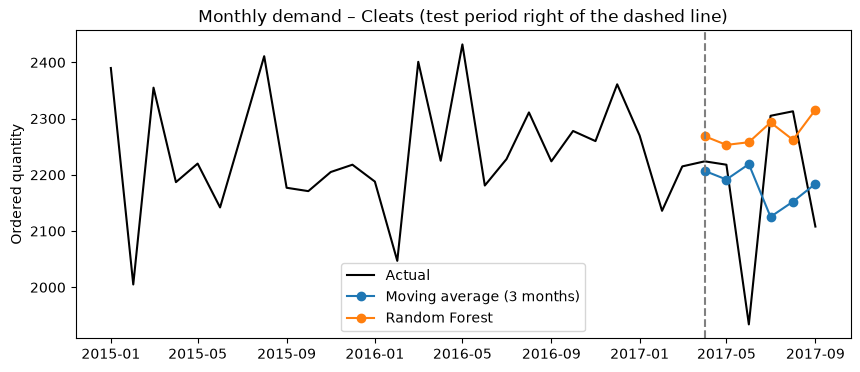

In [8]:
import matplotlib.pyplot as plt

cat = "Cleats"
hist = panel[panel["Category Name"] == cat]
mask = (test["Category Name"] == cat).values

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(hist["period"].dt.to_timestamp(), hist["demand"], label="Actual", color="black")
for name in ["Moving average (3 months)", "Random Forest"]:
    ax.plot(test.loc[mask, "period"].dt.to_timestamp(), np.asarray(preds[name])[mask],
            marker="o", label=name)
ax.axvline(TEST_START.to_timestamp(), linestyle="--", color="grey")
ax.set_title(f"Monthly demand – {cat} (test period right of the dashed line)")
ax.set_ylabel("Ordered quantity")
ax.legend()
plt.show()